<a href="https://colab.research.google.com/github/hrishabh1212/Machine-Learning/blob/main/Single_Linkage_Clustering_Climate_data_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CLIMATE DATASET
    Location_ID  Temperature  Rainfall
0             1        21.49    307.58
1             2        19.59    164.54
2             3        21.94    264.62
3             4        24.57    112.82
4             5        19.30    157.03
..          ...          ...       ...
95           96        31.48   2096.33
96           97        25.54   1779.04
97           98        30.89   2038.43
98           99        29.24   2014.55
99          100        30.47   1714.26

[100 rows x 3 columns]

Total Records: 100


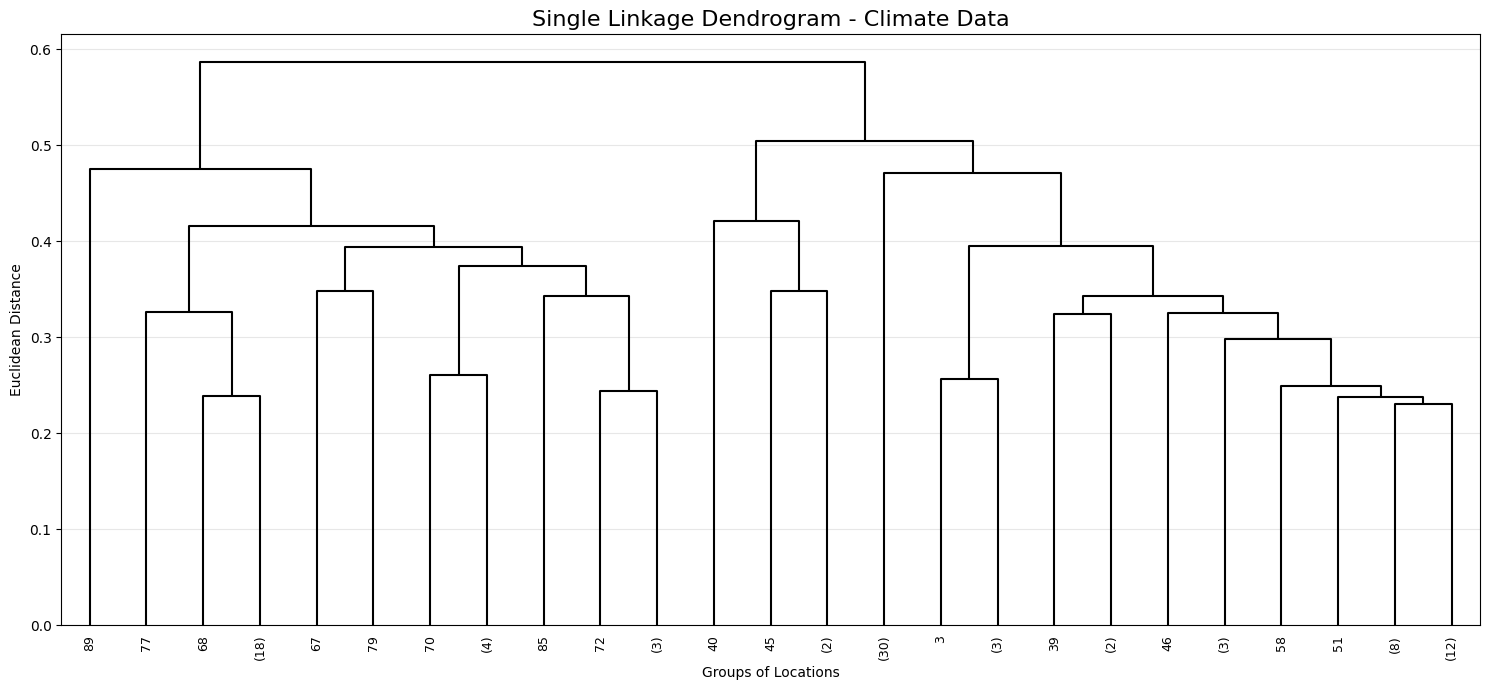


CLUSTERED CLIMATE DATA
    Location_ID  Temperature  Rainfall  Cluster
0             1        21.49    307.58        3
1             2        19.59    164.54        3
2             3        21.94    264.62        3
3             4        24.57    112.82        3
4             5        19.30    157.03        3
..          ...          ...       ...      ...
95           96        31.48   2096.33        1
96           97        25.54   1779.04        1
97           98        30.89   2038.43        1
98           99        29.24   2014.55        1
99          100        30.47   1714.26        1

[100 rows x 4 columns]

CLUSTER COUNTS
Cluster
1    33
2     4
3    63
Name: count, dtype: int64

CLUSTER CENTRES
         Temperature  Rainfall
Cluster                       
1              28.22   2002.38
2              19.39    930.30
3              22.27    545.40


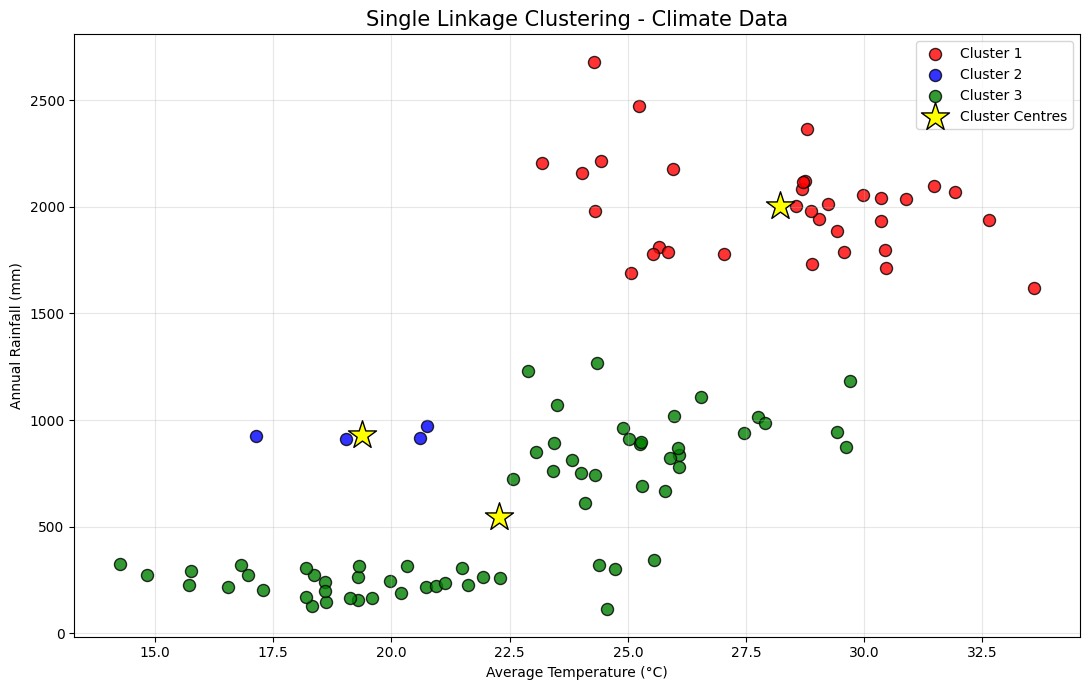


TOTAL RECORDS: 100
NUMBER OF CLUSTERS: 3
LINKAGE METHOD: SINGLE
DISTANCE: EUCLIDEAN

SINGLE LINKAGE CLUSTERING COMPLETED!


In [ ]:

# ================================================
# SINGLE LINKAGE CLUSTERING
# CLIMATE DATASET - 100 RECORDS
# ================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

# STEP 1: GENERATE CLIMATE DATA

np.random.seed(42)

# Dry climate
dry = np.column_stack([
    np.random.normal(20, 3, 34),
    np.random.normal(250, 70, 34)
])

# Moderate climate
moderate = np.column_stack([
    np.random.normal(25, 3, 33),
    np.random.normal(900, 150, 33)
])

# Wet climate
wet = np.column_stack([
    np.random.normal(28, 3, 33),
    np.random.normal(2000, 250, 33)
])

# Combine all records
data = np.vstack([dry, moderate, wet])

data[:, 0] = np.clip(data[:, 0], 5, 40)
data[:, 1] = np.clip(data[:, 1], 50, 3000)

# STEP 2: CREATE DATAFRAME

df = pd.DataFrame(
    data,
    columns=['Temperature', 'Rainfall']
)

df.insert(0, 'Location_ID', range(1, 101))

print("CLIMATE DATASET")
print(df.round(2))

print("\nTotal Records:", len(df))

# STEP 3: SELECT FEATURES

X = df[['Temperature', 'Rainfall']]

# STEP 4: FEATURE SCALING

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# STEP 5: SINGLE LINKAGE MATRIX

linked = linkage(
    X_scaled,
    method='single',
    metric='euclidean'
)

# STEP 6: DENDROGRAM

plt.figure(figsize=(15, 7))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=25,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=9,
    color_threshold=0,
    above_threshold_color='black'
)

plt.title(
    'Single Linkage Dendrogram - Climate Data',
    fontsize=16
)

plt.xlabel('Groups of Locations')
plt.ylabel('Euclidean Distance')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# STEP 7: APPLY SINGLE LINKAGE

model = AgglomerativeClustering(
    n_clusters=3,
    linkage='single',
    metric='euclidean'
)

df['Cluster'] = model.fit_predict(X_scaled) + 1

# STEP 8: DISPLAY CLUSTERS

print("\nCLUSTERED CLIMATE DATA")
print(df.round(2))

print("\nCLUSTER COUNTS")
print(df['Cluster'].value_counts().sort_index())

# STEP 9: CALCULATE CLUSTER CENTRES

centres = df.groupby('Cluster')[
    ['Temperature', 'Rainfall']
].mean()

print("\nCLUSTER CENTRES")
print(centres.round(2))

# STEP 10: 2D VISUALIZATION

plt.figure(figsize=(11, 7))

colors = ['red', 'blue', 'green']

for cluster in sorted(df['Cluster'].unique()):

    group = df[df['Cluster'] == cluster]

    plt.scatter(
        group['Temperature'],
        group['Rainfall'],
        color=colors[cluster - 1],
        s=75,
        edgecolors='black',
        alpha=0.8,
        label=f'Cluster {cluster}'
    )

plt.scatter(
    centres['Temperature'],
    centres['Rainfall'],
    color='yellow',
    marker='*',
    s=450,
    edgecolors='black',
    label='Cluster Centres',
    zorder=5
)

plt.title(
    'Single Linkage Clustering - Climate Data',
    fontsize=15
)

plt.xlabel('Average Temperature (°C)')
plt.ylabel('Annual Rainfall (mm)')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# STEP 11: SAVE DATASET

df.to_csv(
    'Climate_Single_Linkage_100.csv',
    index=False
)

# STEP 12: FINAL OUTPUT

print("\nTOTAL RECORDS:", len(df))
print("NUMBER OF CLUSTERS:", df['Cluster'].nunique())
print("LINKAGE METHOD: SINGLE")
print("DISTANCE: EUCLIDEAN")

print("\nSINGLE LINKAGE CLUSTERING COMPLETED!")
